# Mountain Car -- TD Control Methods (Sutton & Barto, Example 10.1)

A warm-up for deep-RL-style methods: continuous 2D state, discrete actions, function approximation via a small neural network, gradients via `torch.autograd.grad` throughout (never a hand-derived analytical formula).

This notebook covers the **value-based** agents, built up one at a time:
1. Semi-gradient Sarsa (Ch. 10.1)
2. Semi-gradient $n$-step Sarsa (Ch. 10.2)
3. Semi-gradient (one-step) Expected Sarsa
4. Semi-gradient (one-step) Q-learning -- genuinely in "deadly triad" territory (Ch. 11): function approximation + bootstrapping + off-policy, all three at once, with no convergence guarantee (unlike Sarsa/Expected Sarsa, which are on-policy and so avoid the third ingredient)
5. Semi-gradient (one-step) Double Q-learning

The **policy-gradient** agents (policy gradient with a learned baseline, and Actor-Critic with Generalized Advantage Estimation) have their own interface and live separately in `policy_gradient/mountain_car_pg.ipynb`, since they're a different kind of agent entirely -- a learned $\pi(a\mid s,\theta)$, not $\varepsilon$-greedy over $\hat q$.

**Function approximator**: a small MLP taking $(x,\dot x)$ as input, approximating $\hat q(s,a,w)$. Chosen over replicating the book's own tile-coding setup for simplicity and because it's the standard choice for low-dimensional continuous state in modern (deep) RL -- this notebook won't reproduce the book's exact figures, but implements the same algorithms.

## Environment (Example 10.1, pages 244-246)

A car in a valley between two hills must reach a goal at the top of the right hill, but the engine is too weak to climb directly -- it has to first move away from the goal (up the left slope) to build momentum.

**State**: position $x\in[-1.2, 0.5]$, velocity $\dot x\in[-0.07,0.07]$.

**Actions**: three discrete throttle settings -- full reverse ($-1$), zero ($0$), full forward ($+1$).

**Dynamics** (velocity updates first, using the *old* position; then position updates using the *new* velocity):
$$\dot x_{t+1} \doteq \text{bound}\big[\dot x_t + 0.001 A_t - 0.0025\cos(3x_t)\big], \qquad x_{t+1} \doteq \text{bound}\big[x_t + \dot x_{t+1}\big]$$
where `bound` clips to the state ranges above. If $x_{t+1}$ hits the **left** bound ($-1.2$), $\dot x_{t+1}$ is reset to $0$ (the car "bounces," losing all momentum). If $x_{t+1}$ hits the **right** bound ($0.5$), the goal is reached and the episode ends.

**Reward**: $-1$ on every time step, including the terminating one -- there's no bonus for reaching the goal, just the absence of further $-1$'s. Undiscounted ($\gamma=1$), episodic.

**Initial state**: every episode starts at a position drawn uniformly from $[-0.6,-0.4)$, with velocity $0$.

In [1]:
import numpy as np
import torch

POSITION_MIN = -1.2
POSITION_MAX = 0.5
VELOCITY_MIN = -0.07
VELOCITY_MAX = 0.07

REVERSE, ZERO, FORWARD = 0, 1, 2
ACTIONS = [REVERSE, ZERO, FORWARD]
ACTION_VALUES = [-1, 0, 1]  # ACTION_VALUES[a] = the throttle value used in the dynamics equation

START_POSITION_RANGE = (-0.6, -0.4)
GAMMA = 1.0


def reset():
    """Sample a random initial state: position in [-0.6, -0.4), velocity 0."""
    position = np.random.uniform(*START_POSITION_RANGE)
    velocity = 0.0
    return position, velocity


def step(position, velocity, action):
    """One Mountain Car transition (Example 10.1). Returns
    (next_position, next_velocity, reward, done)."""
    throttle = ACTION_VALUES[action]
    velocity_next = velocity + 0.001 * throttle - 0.0025 * np.cos(3 * position)
    velocity_next = np.clip(velocity_next, VELOCITY_MIN, VELOCITY_MAX)

    position_next = position + velocity_next
    done = position_next >= POSITION_MAX
    position_next = np.clip(position_next, POSITION_MIN, POSITION_MAX)

    if position_next == POSITION_MIN:
        velocity_next = 0.0

    reward = -1.0
    return position_next, velocity_next, reward, done

In [2]:
# Sanity check 1: reset() gives the right range
np.random.seed(0)
starts = [reset() for _ in range(1000)]
positions = [s[0] for s in starts]
velocities = [s[1] for s in starts]
assert all(-0.6 <= p < -0.4 for p in positions)
assert all(v == 0.0 for v in velocities)
print("reset() always gives position in [-0.6, -0.4), velocity 0")

reset() always gives position in [-0.6, -0.4), velocity 0


In [3]:
# Sanity check 2: bounds are always respected, from a wide range of random states/actions
np.random.seed(1)
for _ in range(10_000):
    p = np.random.uniform(POSITION_MIN, POSITION_MAX)
    v = np.random.uniform(VELOCITY_MIN, VELOCITY_MAX)
    a = np.random.choice(ACTIONS)
    p_next, v_next, r, done = step(p, v, a)
    assert POSITION_MIN <= p_next <= POSITION_MAX
    assert VELOCITY_MIN <= v_next <= VELOCITY_MAX
print("position and velocity stay within bounds for 10,000 random (state, action) pairs")

position and velocity stay within bounds for 10,000 random (state, action) pairs


In [4]:
# Sanity check 3: hitting the left wall resets velocity to 0
p, v = -1.19, -0.07
p_next, v_next, r, done = step(p, v, REVERSE)
print(f"near left wall, full reverse: position {p} -> {p_next}, velocity {v} -> {v_next}")
assert p_next == POSITION_MIN
assert v_next == 0.0
print("velocity correctly reset to 0 upon hitting the left wall")

near left wall, full reverse: position -1.19 -> -1.2, velocity -0.07 -> 0.0
velocity correctly reset to 0 upon hitting the left wall


In [5]:
# Sanity check 4: the car is genuinely underpowered -- full throttle forward alone
# can never reach the goal, no matter how long you wait (this is the whole point
# of the task: you have to first move away from the goal to build momentum)
np.random.seed(2)
p, v = reset()
steps = 0
done = False
while not done and steps < 2000:
    p, v, r, done = step(p, v, FORWARD)
    steps += 1
print(f"always full forward: reached goal = {done} after {steps} steps")
assert not done
print("confirmed: full throttle forward alone cannot solve the task")

always full forward: reached goal = False after 2000 steps
confirmed: full throttle forward alone cannot solve the task


In [6]:
# Sanity check 5: the task is solvable -- a simple energy-pumping heuristic
# (accelerate in whichever direction the car is already moving) reliably reaches
# the goal well within a reasonable step budget.
#
# Note: step() and heuristic_action() are both fully deterministic -- no
# np.random anywhere in either. The only randomness here is reset()'s random
# starting position; once that's drawn, the whole trajectory (every later
# position, velocity, action, and the exact step count to termination) is
# already fixed. So running 20 trials isn't averaging out stochastic dynamics
# (there are none) -- it's sampling several different starting positions
# across [-0.6, -0.4) to check the heuristic holds up across that whole range,
# not just at one arbitrary point.
def heuristic_action(velocity):
    return FORWARD if velocity >= 0 else REVERSE

np.random.seed(3)
step_counts = []
for trial in range(20):
    p, v = reset()
    steps = 0
    done = False
    while not done and steps < 1000:
        a = heuristic_action(v)
        p, v, r, done = step(p, v, a)
        steps += 1
    assert done, f"trial {trial} failed to reach the goal within 1000 steps"
    step_counts.append(steps)

print(f"energy-pumping heuristic reaches the goal in all 20 trials; "
      f"steps taken: min={min(step_counts)}, mean={np.mean(step_counts):.1f}, max={max(step_counts)}")

energy-pumping heuristic reaches the goal in all 20 trials; steps taken: min=113, mean=119.3, max=125


## 1. Semi-gradient Sarsa (Ch. 10.1)

**The general semi-gradient action-value update** (Eq. 10.1):
$$w_{t+1} \doteq w_t + \alpha\big[U_t - \hat q(S_t,A_t,w_t)\big]\nabla\hat q(S_t,A_t,w_t)$$

**One-step Sarsa's target** is the one-step bootstrapped return (Eq. 10.2):
$$w_{t+1} \doteq w_t + \alpha\big[R_{t+1} + \gamma\hat q(S_{t+1},A_{t+1},w_t) - \hat q(S_t,A_t,w_t)\big]\nabla\hat q(S_t,A_t,w_t)$$

This is **on-policy**: $A_{t+1}$ is the *actual* next action chosen by the same (e.g. $\varepsilon$-greedy) policy being improved -- not a max or an expectation over actions. That's exactly what keeps this method inside the "safe" two-out-of-three corner of the deadly triad (function approximation + bootstrapping, but not off-policy) discussed in the Discussion notes of `Short_Corridor.ipynb` and in this session's conversation.

**Our adaptation:**
- $\hat q(s,a,w)$: a small neural network (`QNetwork`) taking normalized $(x,\dot x)$ and outputting one $q$-value per action, so $\hat q(s,a,w) = \text{network}(s)[a]$.
- $\nabla\hat q(S_t,A_t,w_t)$: computed via `torch.autograd.grad(q_sa, q_network.parameters())`, never a hand-derived formula -- this is what's actually required once $\hat q$ is a nonlinear, many-parameter function, unlike the tabular/linear cases earlier in this project where the gradient was a trivial one-hot or feature vector.
- Action selection: $\varepsilon$-greedy over the network's own current $\hat q(S,\cdot,w)$, with the same random-tie-breaking `epsilon_greedy` helper used in `Windy_Gridworld.ipynb`.
- Implemented **online** -- one real step of interaction, immediately followed by one update, exactly matching the book's own pseudocode (reproduced below), not an offline "collect the episode, then learn" restructuring.

In [16]:
import torch.nn as nn


class QNetwork(nn.Module):
    """A small MLP approximating q_hat(s,a,w): input (position, velocity),
    output one q-value per action."""

    def __init__(self, hidden_size=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden_size), nn.Tanh(),
            nn.Linear(hidden_size, hidden_size), nn.Tanh(),
            nn.Linear(hidden_size, len(ACTIONS)),
        ).double()

    def forward(self, state):
        return self.net(state)


def encode_state(position, velocity):
    """Normalize (position, velocity) to [-1, 1] before feeding the network
    (their raw ranges are over 10x apart, which would otherwise let position
    dominate numerically). Min-max to [0, 1], then scale by 2 and shift by -1
    to land on [-1, 1]; applied separately, with each variable's own bounds."""
    pos_norm = 2 * (position - POSITION_MIN) / (POSITION_MAX - POSITION_MIN) - 1
    vel_norm = 2 * (velocity - VELOCITY_MIN) / (VELOCITY_MAX - VELOCITY_MIN) - 1
    return torch.tensor([pos_norm, vel_norm], dtype=torch.float64)


def q_values_at(q_network, position, velocity):
    """A detached q_hat(s, ., w) lookup for every action -- used for
    epsilon-greedy action selection, never something differentiated through.
    The single, uniform way this notebook reads q-values whenever it only
    needs numbers, not gradients -- instead of ad hoc torch.no_grad()/.numpy()
    blocks scattered inline."""
    with torch.no_grad():
        return q_network(encode_state(position, velocity)).numpy()


def q_sa_value(q_network, position, velocity, action):
    """A detached q_hat(s, a, w) lookup for a single action -- used only for
    bootstrap targets (one-step and n-step alike), which are always fixed
    target values, never something differentiated through."""
    return q_values_at(q_network, position, velocity)[action]


def epsilon_greedy(q_values, epsilon):
    """Same random-tie-breaking epsilon-greedy as Windy_Gridworld.ipynb."""
    if np.random.rand() < epsilon:
        return np.random.choice(ACTIONS)
    best = np.flatnonzero(q_values == q_values.max())
    return np.random.choice(best)


def sgd_update(q_network, q_sa, delta, alpha):
    """w <- w + alpha * delta * grad(q_sa, w) -- plain semi-gradient SGD,
    gradient via torch.autograd.grad, never a hand-derived formula."""
    grads = torch.autograd.grad(q_sa, q_network.parameters())
    with torch.no_grad():
        for param, grad in zip(q_network.parameters(), grads):
            param += alpha * delta * grad

In [17]:
def semi_gradient_sarsa_episode(q_network, alpha, epsilon, gamma=GAMMA, max_steps=1000):
    """One online episode of episodic semi-gradient Sarsa (Eq. 10.1-10.2):
    take a real step, update immediately, repeat."""
    position, velocity = reset()
    state = encode_state(position, velocity)
    q_values = q_values_at(q_network, position, velocity)
    action = epsilon_greedy(q_values, epsilon)

    steps = 0
    while True:
        position_1, velocity_1, reward, done = step(position, velocity, action)        
        steps += 1
        q_sa = q_network(state)[action]  # graph-connected for autograd.grad below -- NOT q_sa_value, which detaches

        if done:
            delta = reward - q_sa.item()
            sgd_update(q_network, q_sa, delta, alpha)
            break

        state_1 = encode_state(position_1, velocity_1)
        q_values_1 = q_values_at(q_network, position_1, velocity_1)
        action_1 = epsilon_greedy(q_values_1, epsilon)
        q_sa_1 = q_values_1[action_1]  # already computed above; q_sa_1 is only ever
                                        # used as a detached number, so no need to
                                        # call the network again just to re-read it
        target = reward + gamma * q_sa_1
        delta = target - q_sa.item()
        sgd_update(q_network, q_sa, delta, alpha)

        position, velocity = position_1, velocity_1
        state = state_1
        action = action_1
        if steps >= max_steps:
            break

    return steps

### Validating -- and reproducing -- the collapse documented below

The cells below aren't a conventional "sanity check that passes cleanly" -- they exist to make Discussion notes item 1 concrete and reproducible, by directly measuring the thing that collapses: the spread of $\hat q(s,\cdot,w)$ across the 3 actions, at a fixed grid of representative states, over the course of training.

In [18]:
# A fixed grid of representative states, used only to measure how well q_hat
# distinguishes the 3 actions during training -- not part of the algorithm itself.
PROBE_GRID = [(p, v) for p in np.linspace(POSITION_MIN, POSITION_MAX, 6)
                      for v in np.linspace(VELOCITY_MIN, VELOCITY_MAX, 3)]


def within_state_action_spread(q_network):
    """Average, across the probe grid, of max_a q_hat(s,a,w) - min_a q_hat(s,a,w).
    Collapsing toward 0 means ~every action looks equally good everywhere --
    epsilon-greedy becomes effectively random regardless of epsilon."""
    vals = [q_values_at(q_network, p, v) for p, v in PROBE_GRID]  # each: shape (3,) -- one q-value per action
    vals = np.array(vals)                        # shape (18, 3) -- 18 probe states x 3 actions
    return (vals.max(axis=1) - vals.min(axis=1)).mean()  # (18,) - (18,) -> (18,), then mean() -> scalar

In [19]:
torch.manual_seed(0)
np.random.seed(0)
q_network = QNetwork()
initial_spread = within_state_action_spread(q_network)
print(f"before training: within-state action spread = {initial_spread:.4f}")

steps_log = []
for ep in range(25):
    steps = semi_gradient_sarsa_episode(q_network, alpha=0.0001, epsilon=0.1, max_steps=1000)
    steps_log.append(steps)

final_spread = within_state_action_spread(q_network)
print("steps per episode:", steps_log)
print(f"final within-state action spread: {final_spread:.4f}")

assert steps_log[0] < 1000, "expected the very first episode to finish quickly, before any collapse"
assert final_spread < initial_spread / 2, "expected the spread to have collapsed by episode 25"
print("\nReproduces the collapse: a handful of normal-looking episodes, then the step "
      "cap every time after, with the within-state spread shrunk to a fraction of its "
      "starting value -- exactly as documented below.")

before training: within-state action spread = 0.3666
steps per episode: [208, 172, 247, 223, 167, 190, 167, 185, 162, 178, 180, 181, 156, 174, 185, 255, 306, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
final within-state action spread: 0.0424

Reproduces the collapse: a handful of normal-looking episodes, then the step cap every time after, with the within-state spread shrunk to a fraction of its starting value -- exactly as documented below.


In [20]:
def semi_gradient_sarsa_episode_opt(q_network, optimizer, epsilon, gamma=GAMMA, max_steps=1000):
    """Same algorithm as semi_gradient_sarsa_episode, but applying the gradient
    through a torch.optim optimizer (e.g. Adam) instead of a plain fixed-alpha
    SGD step -- used only to check the "different optimizer" question below."""
    position, velocity = reset()
    state_vec = encode_state(position, velocity)
    q_values = q_values_at(q_network, position, velocity)
    action = epsilon_greedy(q_values, epsilon)

    steps = 0
    while True:
        position_next, velocity_next, reward, done = step(position, velocity, action)
        steps += 1
        q_sa = q_network(state_vec)[action]  # graph-connected for autograd.grad below -- NOT q_sa_value, which detaches

        if done:
            target = reward
        else:
            state_next_vec = encode_state(position_next, velocity_next)
            q_values_next = q_values_at(q_network, position_next, velocity_next)
            action_next = epsilon_greedy(q_values_next, epsilon)
            q_next = q_sa_value(q_network, position_next, velocity_next, action_next)
            target = reward + gamma * q_next

        delta = target - q_sa.item()
        grads = torch.autograd.grad(q_sa, q_network.parameters())
        optimizer.zero_grad()
        for param, grad in zip(q_network.parameters(), grads):
            param.grad = -delta * grad  # optimizers do param -= lr*grad; we want param += lr*delta*grad
        optimizer.step()

        if done:
            break
        position, velocity = position_next, velocity_next
        state_vec = state_next_vec
        action = action_next
        if steps >= max_steps:
            break

    return steps


torch.manual_seed(0)
np.random.seed(0)
q_network_adam = QNetwork()
optimizer = torch.optim.Adam(q_network_adam.parameters(), lr=1e-4)
adam_steps = [semi_gradient_sarsa_episode_opt(q_network_adam, optimizer, epsilon=0.1, max_steps=1000)
              for _ in range(8)]
print("Adam (lr=1e-4), steps per episode:", adam_steps)
print(f"Adam within-state spread after 8 episodes: {within_state_action_spread(q_network_adam):.4f}")

assert adam_steps[1] >= 1000 or adam_steps[2] >= 1000, "expected Adam to collapse within the first few episodes"
print("\nConfirms Adam collapses faster than plain SGD, not slower -- ruling out "
      "'switch optimizer' as the fix (see Discussion notes item 1).")

Adam (lr=1e-4), steps per episode: [200, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
Adam within-state spread after 8 episodes: 0.0186

Confirms Adam collapses faster than plain SGD, not slower -- ruling out 'switch optimizer' as the fix (see Discussion notes item 1).


## 2. Semi-gradient $n$-step Sarsa (Ch. 10.2)

**The $n$-step return for action values** (Eq. 10.4):
$$G_{t:t+n} \doteq R_{t+1}+\gamma R_{t+2}+\dots+\gamma^{n-1}R_{t+n}+\gamma^n\hat q(S_{t+n},A_{t+n},w_{t+n-1}), \qquad t+n<T$$
(with $G_{t:t+n}\doteq G_t$ if $t+n\ge T$, as usual).

**The $n$-step update** (Eq. 10.5):
$$w_{t+n} \doteq w_{t+n-1} + \alpha\big[G_{t:t+n}-\hat q(S_t,A_t,w_{t+n-1})\big]\nabla\hat q(S_t,A_t,w_{t+n-1}), \qquad 0\le t<T$$

**The pseudocode** (reproduced from the book, page 268):
```
Episodic semi-gradient n-step Sarsa for estimating q_hat ~ q* or q_pi

Input: a differentiable action-value function parameterization q_hat : S x A x R^d -> R
Input: a policy pi (if estimating q_pi)
Algorithm parameters: step size alpha > 0, small epsilon > 0, a positive integer n
Initialize value-function weights w in R^d arbitrarily (e.g., w = 0)
All store and access operations (S_t, A_t, and R_t) can take their index mod n+1

Loop for each episode:
    Initialize and store S_0 != terminal
    Select and store an action A_0 ~ pi(.|S_0) or epsilon-greedy wrt q_hat(S_0, ., w)
    T <- infinity
    Loop for t = 0, 1, 2, ... :
        If t < T, then:
            Take action A_t
            Observe and store the next reward as R_{t+1} and the next state as S_{t+1}
            If S_{t+1} is terminal, then:
                T <- t + 1
            else:
                Select and store A_{t+1} ~ pi(.|S_{t+1}) or epsilon-greedy wrt q_hat(S_{t+1}, ., w)
        tau <- t - n + 1    (tau is the time whose estimate is being updated)
        If tau >= 0:
            G <- Sum_{i=tau+1}^{min(tau+n,T)} gamma^{i-tau-1} R_i
            If tau + n < T, then: G <- G + gamma^n q_hat(S_{tau+n}, A_{tau+n}, w)    (this G is G_{tau:tau+n})
            w <- w + alpha [G - q_hat(S_tau, A_tau, w)] grad(q_hat(S_tau, A_tau, w))
    Until tau = T - 1
```

This has the **same $t$/$\tau$ structure** as section 1's pseudocode (and `n_step_td_prediction.ipynb`'s own n-step TD prediction pseudocode) -- just with $(S,A)$ pairs instead of $S$ alone, and an action selected right after observing each new state.

**Our adaptation:**
- $\hat q(s,a,w)$: a `QNetwork`, same as section 1 -- a small MLP, input normalized $(x,\dot x)$, one output per action.
- $\nabla\hat q(S_\tau,A_\tau,w)$: computed via `torch.autograd.grad`, reusing section 1's `sgd_update` helper unchanged.
- Action selection: section 1's `epsilon_greedy` helper, unchanged.
- Detached q-value lookups (never differentiated through): `q_values_at` (all actions, for $\varepsilon$-greedy) and `q_sa_value` (one action, for bootstrap targets) -- both introduced in section 1's infra cell, used uniformly everywhere this notebook needs a plain number rather than a gradient-bound tensor.
- **Online**, step by step, exactly matching the pseudocode above -- not an offline "generate the episode, then learn" restructuring. This is required here, not just stylistic: behavior depends on the still-evolving $\hat q$, so the whole episode can't be known in advance the way it could for prediction (`n_step_td_prediction.ipynb` could afford to go offline for exactly this reason -- no policy there ever depended on the thing being learned).
- **Three implementations below**, isolating two independent design choices -- how $G$ is computed, and how much memory is kept -- to show that neither changes *what* is computed, only *how*:
  - **Version 3** (`semi_gradient_n_step_sarsa_episode`): $O(1)$-per-update sliding-window recursion for $G$; plain growing-list storage.
  - **Version 1** (`semi_gradient_n_step_sarsa_episode_pseudocode`): $O(n)$-per-update direct recomputation of $G$, following the book's pseudocode line by line; plain growing-list storage.
  - **Version 2** (`semi_gradient_n_step_sarsa_episode_buffered`): same $O(n)$-per-update direct recomputation as Version 1, but now also following the book's storage note literally -- $S_t,A_t,R_t$ kept in circular buffers indexed mod $n+1$, so memory is $O(n)$ instead of $O(T)$.

**Equation/pseudocode $\leftrightarrow$ code (both versions):**

| Equation / pseudocode | Code |
|---|---|
| $t$ | `t` |
| $\tau \leftarrow t-n+1$ | `tau = t - n + 1` |
| $S_t, A_t, R_t$ | `states[t], actions[t], rewards[t]` (rewards 1-indexed, as in section 1) |
| "If $\tau\ge 0$" | `if tau >= 0:` |
| $\sum_{i=\tau+1}^{\min(\tau+n,T)}\gamma^{i-\tau-1}R_i$ | the $G$/`reward_sum` term (computed differently per version -- see below) |
| "If $\tau+n<T$: $G\leftarrow G+\gamma^n\hat q(S_{\tau+n},A_{\tau+n},w)$" | `if tau + n < T: target/G += gamma**n * q_sa_value(...)` |
| $\hat q(S_\tau,A_\tau,w)$ | `q_sa = q_network(encode_state(*states[tau]))[actions[tau]]` |
| $w\leftarrow w+\alpha[G-\hat q(S_\tau,A_\tau,w)]\nabla\hat q(S_\tau,A_\tau,w)$ | `sgd_update(q_network, q_sa, delta, alpha)` |
| "Until $\tau=T-1$" | `if tau == T - 1: break` |

### Version 1: pseudocode-faithful direct computation ($O(n)$ per update)

Implements the pseudocode on page 268 as literally as possible:
- $G_{\tau:\tau+n} = \sum_{i=\tau+1}^{\min(\tau+n,T)}\gamma^{i-\tau-1}R_i\;\big[+\,\gamma^n\hat q(S_{\tau+n},A_{\tau+n},w)\text{ if }\tau+n<T\big]$ is recomputed term by term, from scratch, at every $\tau$ -- no incremental state carried between updates, at the cost of $O(n)$ work per update ($O(nT)$ per episode) instead of Version 3's $O(1)$ per update.
- $S_t, A_t, R_t$ are stored in plain growing lists, same as Version 3, indexed directly by $t$ -- *not* the pseudocode's circular buffers (mod $n+1$). The book notes storage can take index mod $n+1$ purely as a memory optimization (bounded $O(n)$ instead of $O(T)$); that's an orthogonal concern from the $O(n)$-vs-$O(1)$ **compute** question this comparison is actually about, so it's isolated separately in Version 2 below rather than mixed in here.

**Equation/pseudocode $\leftrightarrow$ code:**

| Equation / pseudocode | Code |
|---|---|
| $S_t, A_t, R_t$ | `states[t], actions[t], rewards[t]` |
| $G \leftarrow \sum_{i=\tau+1}^{\min(\tau+n,T)}\gamma^{i-\tau-1}R_i$ | `G = sum(gamma**(i - tau - 1) * rewards[i] for i in range(tau + 1, upper + 1))` |
| "If $\tau+n<T$: $G\leftarrow G+\gamma^n\hat q(S_{\tau+n},A_{\tau+n},w)$" | `if tau + n < T: G += gamma**n * q_sa_value(...)` |
| $w\leftarrow w+\alpha[G-\hat q(S_\tau,A_\tau,w)]\nabla\hat q(S_\tau,A_\tau,w)$ | `sgd_update(q_network, q_sa, G - q_sa.item(), alpha)` |

Versions 1, 2, and 3 must all agree exactly, for every $n$ and every seed -- validated below.

In [21]:
def semi_gradient_n_step_sarsa_episode_pseudocode(q_network, n, alpha, epsilon, gamma=GAMMA, max_steps=1000):
    """Version 1. Same algorithm as semi_gradient_n_step_sarsa_episode (Eq.
    10.4-10.5), but following the book's pseudocode (p. 268) as literally as
    possible for the *compute* side: G is recomputed directly, term by term,
    every tau (O(n) per update), unlike Version 3's O(1) sliding window.
    Storage uses plain growing lists (same as Version 3), not the
    pseudocode's circular (mod n+1) buffers -- that's a separate, orthogonal
    memory optimization, skipped here for simplicity. This version exists to
    make the mapping from equations to code unambiguous, with no shortcuts
    on the G computation itself; semi_gradient_n_step_sarsa_episode (Version
    A) is the one actually meant to be used, since it does the same
    computation in O(1) per update."""
    position, velocity = reset()
    states = [(position, velocity)]   # states[k] = S_k
    actions = []                       # actions[k] = A_k
    rewards = [None]                   # rewards[k] = R_k for k >= 1; rewards[0] unused placeholder

    q_values = q_values_at(q_network, position, velocity)
    actions.append(epsilon_greedy(q_values, epsilon))   # A_0

    T = float("inf")
    t = 0
    real_steps = 0

    while True:
        if t < T:
            position, velocity, reward, done = step(position, velocity, actions[t])
            rewards.append(reward)
            states.append((position, velocity))
            real_steps += 1
            if done:
                T = t + 1
            else:
                q_values_next = q_values_at(q_network, position, velocity)
                actions.append(epsilon_greedy(q_values_next, epsilon))

        tau = t - n + 1   # tau is the time whose estimate is being updated
        if tau >= 0:
            upper = min(tau + n, T)
            G = sum(gamma ** (i - tau - 1) * rewards[i] for i in range(tau + 1, upper + 1))
            if tau + n < T:
                pos_boot, vel_boot = states[tau + n]
                a_boot = actions[tau + n]
                G += (gamma ** n) * q_sa_value(q_network, pos_boot, vel_boot, a_boot)

            pos_tau, vel_tau = states[tau]
            a_tau = actions[tau]
            q_sa = q_network(encode_state(pos_tau, vel_tau))[a_tau]  # graph-connected for autograd.grad below -- NOT q_sa_value, which detaches
            delta = G - q_sa.item()
            sgd_update(q_network, q_sa, delta, alpha)

        if tau == T - 1:
            break
        if real_steps >= max_steps and T == float("inf"):
            break
        t += 1

    return real_steps

### Version 2: pseudocode-faithful, bounded ($O(n)$-per-update) storage via circular buffers

Same $G$ computation as Version 1 (direct $O(n)$ recomputation, no sliding-window shortcut) -- the only thing that changes here is *how much is remembered*. The pseudocode's own note: *"All store and access operations ($S_t$, $A_t$, and $R_t$) can take their index mod $n+1$"* is a memory optimization, orthogonal to the $O(1)$-vs-$O(n)$ compute question Versions 1 and 3 are about: at any point in the loop, an update only ever reads back as far as $S_\tau, A_\tau$ where $\tau=t-n+1$ -- i.e. at most $n+1$ distinct time indices ($\tau, \tau+1, \dots, \tau+n$) are ever live at once. A circular buffer of length $n+1$ is exactly large enough to hold them without collision, and without ever growing with the episode length $T$.

**Equation/pseudocode $\leftrightarrow$ code:**

| Equation / pseudocode | Code |
|---|---|
| "All store and access operations ... can take their index mod $n+1$" | `buf = n + 1`; `states[t % buf], actions[t % buf], rewards[t % buf]` |
| $G \leftarrow \sum_{i=\tau+1}^{\min(\tau+n,T)}\gamma^{i-\tau-1}R_i$ | `G = sum(gamma**(i - tau - 1) * rewards[i % buf] for i in range(tau + 1, upper + 1))` |
| "If $\tau+n<T$: $G\leftarrow G+\gamma^n\hat q(S_{\tau+n},A_{\tau+n},w)$" | `if tau + n < T: G += gamma**n * q_sa_value(states[(tau+n) % buf], actions[(tau+n) % buf])` |
| $\hat q(S_\tau,A_\tau,w)$ | `q_network(encode_state(*states[tau % buf]))[actions[tau % buf]]` |

Versions 1, 2, and 3 must all agree exactly, for every $n$ and every seed -- validated below.

In [22]:
def semi_gradient_n_step_sarsa_episode_buffered(q_network, n, alpha, epsilon, gamma=GAMMA, max_steps=1000):
    """Version 2. Same G computation as Version 1 (direct O(n) recomputation
    every tau), but storage follows the pseudocode's own memory optimization
    literally: S_t, A_t, R_t live in circular buffers of length n+1, indexed
    mod (n+1), instead of growing lists -- bounded O(n) memory regardless of
    episode length T. Still produces the exact same updates as Versions 1
    and 3; only the bookkeeping differs."""
    buf = n + 1
    states = [None] * buf
    actions = [None] * buf
    rewards = [None] * buf

    position, velocity = reset()
    states[0 % buf] = (position, velocity)
    q_values = q_values_at(q_network, position, velocity)
    actions[0 % buf] = epsilon_greedy(q_values, epsilon)

    T = float("inf")
    t = 0
    real_steps = 0

    while True:
        if t < T:
            position, velocity, reward, done = step(position, velocity, actions[t % buf])
            real_steps += 1
            rewards[(t + 1) % buf] = reward
            states[(t + 1) % buf] = (position, velocity)
            if done:
                T = t + 1
            else:
                q_values_next = q_values_at(q_network, position, velocity)
                actions[(t + 1) % buf] = epsilon_greedy(q_values_next, epsilon)

        tau = t - n + 1   # tau is the time whose estimate is being updated
        if tau >= 0:
            upper = min(tau + n, T)
            G = sum(gamma ** (i - tau - 1) * rewards[i % buf] for i in range(tau + 1, upper + 1))
            if tau + n < T:
                pos_boot, vel_boot = states[(tau + n) % buf]
                a_boot = actions[(tau + n) % buf]
                G += (gamma ** n) * q_sa_value(q_network, pos_boot, vel_boot, a_boot)

            pos_tau, vel_tau = states[tau % buf]
            a_tau = actions[tau % buf]
            q_sa = q_network(encode_state(pos_tau, vel_tau))[a_tau]  # graph-connected for autograd.grad below -- NOT q_sa_value, which detaches
            delta = G - q_sa.item()
            sgd_update(q_network, q_sa, delta, alpha)

        if tau == T - 1:
            break
        if real_steps >= max_steps and T == float("inf"):
            break
        t += 1

    return real_steps

### Version 3: efficient sliding-window $G$ computation ($O(1)$ per update)

Recomputing $\sum_{i=\tau+1}^{\min(\tau+n,T)}\gamma^{i-\tau-1}R_i$ from scratch at every $\tau$ costs $O(n)$ per update, $O(nT)$ per episode. Define the *reward-sum* part of the return,
$$W_\tau \doteq \sum_{i=\tau+1}^{\min(\tau+n,T)} \gamma^{\,i-\tau-1} R_i, \qquad G_{\tau:\tau+n} = W_\tau + \gamma^n\hat q(S_{\tau+n},A_{\tau+n},w)\cdot\mathbb{1}[\tau+n<T]$$

**Deriving the recursion from $W_\tau$ to $W_{\tau+1}$.** Away from the end of the episode (i.e. $\tau+1+n\le T$):
$$W_\tau = R_{\tau+1} + \gamma R_{\tau+2} + \dots + \gamma^{n-1}R_{\tau+n}, \qquad W_{\tau+1} = R_{\tau+2} + \gamma R_{\tau+3} + \dots + \gamma^{n-1}R_{\tau+n+1}$$
Dropping $W_\tau$'s oldest (undiscounted) term $R_{\tau+1}$ and dividing the rest by $\gamma$ shifts every surviving exponent down by exactly one -- turning $W_\tau$'s tail into $W_{\tau+1}$'s leading terms:
$$\frac{W_\tau - R_{\tau+1}}{\gamma} = R_{\tau+2} + \gamma R_{\tau+3} + \dots + \gamma^{n-2}R_{\tau+n} = W_{\tau+1} - \gamma^{n-1}R_{\tau+n+1}$$
Rearranging gives the recursion actually used in code:
$$W_{\tau+1} = \frac{W_\tau - R_{\tau+1}}{\gamma} + \gamma^{n-1}R_{\tau+n+1} \qquad\text{(add the new term only if }\tau+1+n\le T\text{, otherwise the window just shrinks)}$$

**Why dividing by $\gamma$, intuitively:** every reward that survives from window $\tau$ into window $\tau+1$ is now one step closer to the window's (new) start, so its discount exponent must drop by exactly 1. Dividing the whole remaining sum by $\gamma$ once does this for *every* surviving term simultaneously, in $O(1)$ -- instead of recomputing each term's exponent individually, which is what makes Version 1 below cost $O(n)$. This is the same trick as `n_step_td_prediction.ipynb` section 10; only the bootstrap term differs here ($\gamma^n\hat q(S_{\tau+n},A_{\tau+n},w)$ instead of $\gamma^n\hat v(S_{\tau+n},w)$).

**Matching the code's own variable naming.** The code names the window it's *about to compute* $\tau$ -- not $\tau+1$ -- and reaches back to the window left over from $\tau-1$. Relabeling the boxed recursion above (substitute $\tau\to\tau-1$, so "the new window" is simply called $\tau$ again, matching the code's `tau` directly) gives:
$$W_\tau = \frac{W_{\tau-1} - R_\tau}{\gamma} + \gamma^{n-1}R_{\tau+n} \qquad\text{(add the new term only if }\tau+n\le T\text{)}$$
This is the form that maps onto code with no index shift left to track -- $R_\tau\leftrightarrow$ `rewards[tau]`, $R_{\tau+n}\leftrightarrow$ `rewards[tau+n]`, directly.

**Equation $\leftrightarrow$ code:**

| Equation | Code |
|---|---|
| $W_\tau$ | `reward_sum` |
| $W_0 = \sum_{i=1}^{\min(n,T)}\gamma^{\,i-1}R_i$ (computed directly, once) | `if reward_sum is None: reward_sum = sum(...)` |
| $W_\tau = \dfrac{W_{\tau-1} - R_\tau}{\gamma} + \gamma^{n-1}R_{\tau+n}$ | `reward_sum = (reward_sum - rewards[tau]) / gamma`; `if tau + n <= T: reward_sum += gamma**(n-1) * rewards[tau+n]` |

In [23]:
def semi_gradient_n_step_sarsa_episode(q_network, n, alpha, epsilon, gamma=GAMMA, max_steps=1000):
    """Version 3. One online episode of episodic semi-gradient n-step Sarsa
    (Eq. 10.4-10.5), with the n-step return's reward-sum W_tau computed via
    the O(1) sliding-window recursion derived above, instead of a fresh O(n)
    sum at every tau (that's Version 1, semi_gradient_n_step_sarsa_episode_pseudocode,
    below)."""
    position, velocity = reset()
    states = [(position, velocity)]   # states[k] = S_k
    actions = []                       # actions[k] = A_k
    rewards = [None]                   # rewards[k] = R_k for k >= 1; rewards[0] unused placeholder

    q_values = q_values_at(q_network, position, velocity)
    actions.append(epsilon_greedy(q_values, epsilon))   # A_0

    T = float("inf")
    t = 0
    real_steps = 0
    reward_sum = None   # W_tau = Sigma_{i=tau+1}^{min(tau+n,T)} gamma^{i-tau-1} R_i, for the current tau

    while True:
        if t < T:
            position, velocity, reward, done = step(position, velocity, actions[t])
            rewards.append(reward)
            states.append((position, velocity))
            real_steps += 1
            if done:
                T = t + 1
            else:
                q_values_next = q_values_at(q_network, position, velocity)
                actions.append(epsilon_greedy(q_values_next, epsilon))

        tau = t - n + 1   # tau is the time whose estimate is being updated
        if tau >= 0:
            upper = min(tau + n, T)
            if reward_sum is None:
                # W_0: compute the window sum directly, once
                reward_sum = sum(gamma ** (i - tau - 1) * rewards[i] for i in range(tau + 1, upper + 1))
            else:
                # W_tau = (W_{tau-1} - R_tau) / gamma  [+ gamma^{n-1} R_{tau+n} if it exists]
                reward_sum = (reward_sum - rewards[tau]) / gamma
                if tau + n <= T:
                    reward_sum += (gamma ** (n - 1)) * rewards[tau + n]

            target = reward_sum
            if tau + n < T:
                pos_boot, vel_boot = states[tau + n]
                a_boot = actions[tau + n]
                target += (gamma ** n) * q_sa_value(q_network, pos_boot, vel_boot, a_boot)

            pos_tau, vel_tau = states[tau]
            a_tau = actions[tau]
            q_sa = q_network(encode_state(pos_tau, vel_tau))[a_tau]  # graph-connected for autograd.grad below -- NOT q_sa_value, which detaches
            delta = target - q_sa.item()
            sgd_update(q_network, q_sa, delta, alpha)

        if tau == T - 1:
            break
        if real_steps >= max_steps and T == float("inf"):
            break   # safety valve: give up without ever having reached a real terminal state
        t += 1

    return real_steps

### Validating that all three implementations agree

Cross-checks, in the same spirit as `n_step_td_prediction.ipynb`: Version 3 (efficient $O(1)$), Version 1 ($O(n)$, growing lists), and Version 2 ($O(n)$, bounded circular buffers) must all match exactly -- and all three must reduce to section 1's already-validated one-step Sarsa exactly at $n=1$.

In [24]:
# Cross-check 1: Version 3 (efficient, O(1) per update) vs Version 1
# (pseudocode-faithful, O(n) per update, growing lists) vs Version 2 (same
# O(n) G computation as Version 1, but bounded circular-buffer storage) -- same
# seed, same initial network, all three must match exactly: they all
# compute the same G_{tau:tau+n}, just via different bookkeeping.
mismatches = 0
for n in [1, 2, 4, 8, 20]:
    for seed in range(10):
        torch.manual_seed(seed); np.random.seed(seed)
        net_a = QNetwork()
        steps_a = [semi_gradient_n_step_sarsa_episode(net_a, n=n, alpha=0.0001, epsilon=0.1, max_steps=300)
                   for _ in range(5)]

        torch.manual_seed(seed); np.random.seed(seed)
        net_b = QNetwork()
        steps_b = [semi_gradient_n_step_sarsa_episode_pseudocode(net_b, n=n, alpha=0.0001, epsilon=0.1, max_steps=300)
                   for _ in range(5)]

        torch.manual_seed(seed); np.random.seed(seed)
        net_c = QNetwork()
        steps_c = [semi_gradient_n_step_sarsa_episode_buffered(net_c, n=n, alpha=0.0001, epsilon=0.1, max_steps=300)
                   for _ in range(5)]

        p_a = torch.cat([p.flatten() for p in net_a.parameters()])
        p_b = torch.cat([p.flatten() for p in net_b.parameters()])
        p_c = torch.cat([p.flatten() for p in net_c.parameters()])
        if steps_a != steps_b or steps_a != steps_c \
                or not torch.allclose(p_a, p_b) or not torch.allclose(p_a, p_c):
            mismatches += 1
            print(f"mismatch at n={n}, seed={seed}")

assert mismatches == 0
print("Versions 1, 2, and 3 all match exactly, "
      "across n in {1,2,4,8,20} x 10 seeds (50 combinations).")

Versions 1, 2, and 3 all match exactly, across n in {1,2,4,8,20} x 10 seeds (50 combinations).


In [25]:
# Cross-check 2: n=1 must match section 1's semi_gradient_sarsa_episode
# exactly, for Versions 1, 2, and 3.
mismatches = 0
for seed in range(20):
    torch.manual_seed(seed); np.random.seed(seed)
    net_one_step = QNetwork()
    steps_one_step = [semi_gradient_sarsa_episode(net_one_step, alpha=0.0001, epsilon=0.1, max_steps=300)
                       for _ in range(5)]

    torch.manual_seed(seed); np.random.seed(seed)
    net_a_n1 = QNetwork()
    steps_a_n1 = [semi_gradient_n_step_sarsa_episode(net_a_n1, n=1, alpha=0.0001, epsilon=0.1, max_steps=300)
                  for _ in range(5)]

    torch.manual_seed(seed); np.random.seed(seed)
    net_b_n1 = QNetwork()
    steps_b_n1 = [semi_gradient_n_step_sarsa_episode_pseudocode(net_b_n1, n=1, alpha=0.0001, epsilon=0.1, max_steps=300)
                  for _ in range(5)]

    torch.manual_seed(seed); np.random.seed(seed)
    net_c_n1 = QNetwork()
    steps_c_n1 = [semi_gradient_n_step_sarsa_episode_buffered(net_c_n1, n=1, alpha=0.0001, epsilon=0.1, max_steps=300)
                  for _ in range(5)]

    p1 = torch.cat([p.flatten() for p in net_one_step.parameters()])
    p2 = torch.cat([p.flatten() for p in net_a_n1.parameters()])
    p3 = torch.cat([p.flatten() for p in net_b_n1.parameters()])
    p4 = torch.cat([p.flatten() for p in net_c_n1.parameters()])
    if steps_one_step != steps_a_n1 or steps_one_step != steps_b_n1 or steps_one_step != steps_c_n1 \
            or not torch.allclose(p1, p2) or not torch.allclose(p1, p3) or not torch.allclose(p1, p4):
        mismatches += 1
        print(f"mismatch at seed={seed}")

assert mismatches == 0
print("n=1 matches section 1's one-step Sarsa exactly, for Versions 1, 2, "
      "and 3, across 20 seeds.")

n=1 matches section 1's one-step Sarsa exactly, for Versions 1, 2, and 3, across 20 seeds.


### Demonstration run ($n=4$)

A deliberately cherry-picked $(\text{seed},\alpha)$ combination, not a claim of robustness -- see Discussion notes items 3 and 4 for why a universally-stable $\alpha$ wasn't found for this architecture, across seeds or across $n$.

In [26]:
torch.manual_seed(0)
np.random.seed(0)
q_network_n4 = QNetwork()
steps_log = [semi_gradient_n_step_sarsa_episode(q_network_n4, n=4, alpha=5e-6, epsilon=0.1, max_steps=500)
             for _ in range(60)]
spread = within_state_action_spread(q_network_n4)
print("n=4, alpha=5e-6, seed=0, steps per episode:")
print(steps_log)
print(f"within-state action spread after 60 episodes: {spread:.4f}")

n=4, alpha=5e-6, seed=0, steps per episode:
[213, 327, 224, 216, 218, 248, 256, 224, 287, 272, 222, 253, 284, 269, 246, 285, 205, 196, 262, 130, 230, 139, 202, 201, 180, 172, 160, 206, 314, 217, 170, 174, 165, 242, 167, 244, 159, 230, 177, 164, 162, 165, 169, 192, 197, 193, 226, 189, 161, 161, 232, 194, 188, 191, 219, 227, 160, 225, 171, 222]
within-state action spread after 60 episodes: 0.0812


### Comparing $n=4$ and $n=8$: training curve vs. greedy-policy evaluation

The demonstration above looks healthy for 60 episodes, but that's measuring the wrong thing if the goal is "is $n=4$ or $n=8$ learning a better policy": `steps_log` is the length of an **online, $\varepsilon$-greedy, still-learning** episode, which conflates three things -- the current value function's quality, 10% random exploration noise, and whatever learning happens *during* that same episode. A clean comparison needs to isolate the first of those.

**Fix: evaluate separately from training.** Periodically snapshot the network and run one $\varepsilon=0$ (pure greedy), no-learning rollout. That measures the policy the agent would actually act on, right now, with no noise and no further updates -- directly comparable across $n$.

In [27]:
def evaluate_greedy_policy(q_network, max_steps=500):
    """One rollout with epsilon=0 (pure greedy) and no weight updates --
    measures the CURRENT policy's quality, decoupled from exploration noise
    and from any learning happening mid-episode. Returns steps taken (equal
    to max_steps if the goal was never reached within budget)."""
    position, velocity = reset()
    steps = 0
    while True:
        q_values = q_values_at(q_network, position, velocity)
        action = epsilon_greedy(q_values, epsilon=0.0)
        position, velocity, reward, done = step(position, velocity, action)
        steps += 1
        if done:
            return steps
        if steps >= max_steps:
            return max_steps

**Baseline check.** Before comparing $n=4$ vs $n=8$, it's worth knowing what "no learning at all" looks like under both extremes: a pure-greedy rollout of an *untrained* network, and a pure-random policy with no network at all.

In [28]:
def run_random_policy(max_steps=500, seed=0):
    """Pure random action selection, no network, no learning at all -- a
    baseline for whether a 'trained' greedy policy beats pure chance."""
    rng = np.random.RandomState(seed)
    position, velocity = reset()
    steps = 0
    while True:
        action = rng.choice(ACTIONS)
        position, velocity, reward, done = step(position, velocity, action)
        steps += 1
        if done:
            return steps
        if steps >= max_steps:
            return max_steps


untrained_steps = []
for seed in range(5):
    torch.manual_seed(seed)
    np.random.seed(seed)
    net = QNetwork()
    untrained_steps.append(evaluate_greedy_policy(net, max_steps=500))
print("Untrained network, greedy (epsilon=0), 5 seeds, steps:", untrained_steps)

random_steps = [run_random_policy(max_steps=500, seed=s) for s in range(50)]
random_successes = sum(1 for s in random_steps if s < 500)
print(f"Pure random policy, 50 trials, max_steps=500: {random_successes}/50 reached the goal.")

Untrained network, greedy (epsilon=0), 5 seeds, steps: [500, 500, 500, 500, 500]
Pure random policy, 50 trials, max_steps=500: 0/50 reached the goal.


**The comparison.** 5 seeds per $n$, $\alpha=5\times10^{-6}$ for both (the best found for either $n$ across an extensive sweep -- see Discussion notes item 5), 100 training episodes, with a greedy evaluation every 5 episodes.

In [29]:
import matplotlib.pyplot as plt

ALPHA = 5e-6
SEEDS = range(5)
N_EPISODES = 100
EVAL_EVERY = 5
MAX_STEPS = 500

comparison_results = {}
for n in [4, 8]:
    comparison_results[n] = {"train_steps": [], "eval_curve": []}
    for seed in SEEDS:
        torch.manual_seed(seed)
        np.random.seed(seed)
        net = QNetwork()
        train_steps = []
        eval_curve = [evaluate_greedy_policy(net, MAX_STEPS)]
        for ep in range(N_EPISODES):
            steps = semi_gradient_n_step_sarsa_episode(net, n=n, alpha=ALPHA, epsilon=0.1, max_steps=MAX_STEPS)
            train_steps.append(steps)
            if (ep + 1) % EVAL_EVERY == 0:
                eval_curve.append(evaluate_greedy_policy(net, MAX_STEPS))
        comparison_results[n]["train_steps"].append(train_steps)
        comparison_results[n]["eval_curve"].append(eval_curve)

print(f"Done: n in {{4, 8}}, {len(list(SEEDS))} seeds each, {N_EPISODES} episodes, alpha={ALPHA}.")

Done: n in {4, 8}, 5 seeds each, 100 episodes, alpha=5e-06.


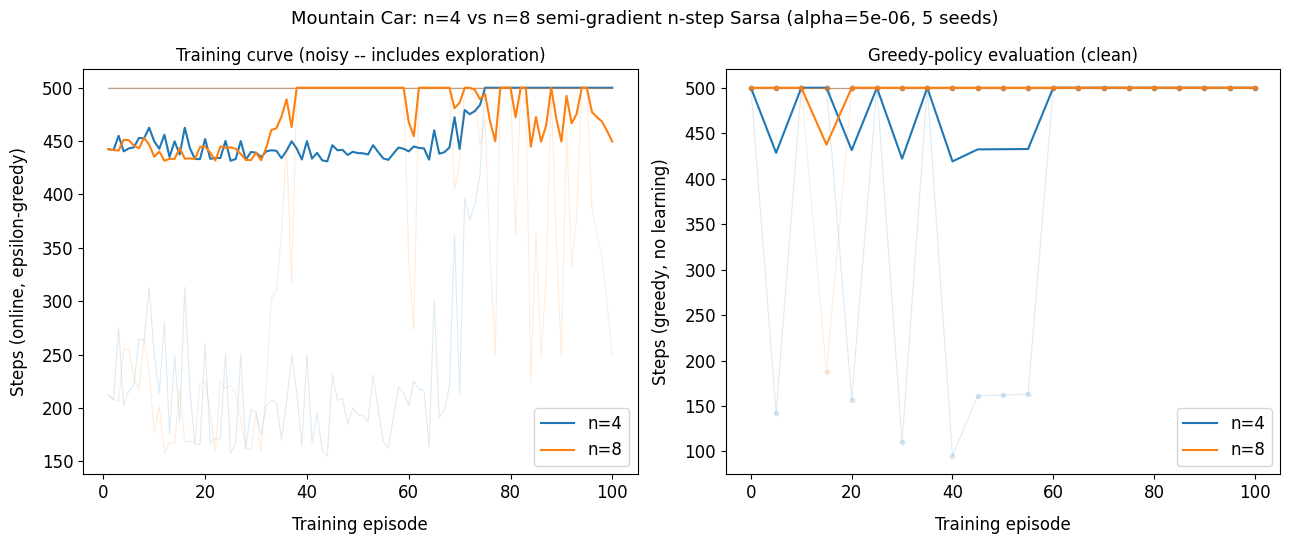

In [30]:
def adjustAxeProperties(ax_obj, x_fontsize, x_rotation, y_fontsize, y_rotation):
    for tick in ax_obj.xaxis.get_major_ticks():
        tick.label1.set_fontsize(x_fontsize)
        tick.label1.set_rotation(x_rotation)
    for tick in ax_obj.yaxis.get_major_ticks():
        tick.label1.set_fontsize(y_fontsize)
        tick.label1.set_rotation(y_rotation)


fontsize = 12
colors = {4: "tab:blue", 8: "tab:orange"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for n in [4, 8]:
    train_arr = np.array(comparison_results[n]["train_steps"])  # shape (seeds, episodes)
    for row in train_arr:
        axes[0].plot(np.arange(1, N_EPISODES + 1), row, color=colors[n], alpha=0.15, linewidth=0.8)
    axes[0].plot(np.arange(1, N_EPISODES + 1), train_arr.mean(axis=0), color=colors[n], label=f"n={n}")
axes[0].set_xlabel("Training episode", fontsize=fontsize, labelpad=10)
axes[0].set_ylabel("Steps (online, epsilon-greedy)", fontsize=fontsize, labelpad=10)
axes[0].set_title("Training curve (noisy -- includes exploration)", fontsize=fontsize)
adjustAxeProperties(axes[0], fontsize, 0, fontsize, 0)
axes[0].legend(loc="best", fontsize=fontsize)

eval_episodes = np.arange(0, N_EPISODES + 1, EVAL_EVERY)
for n in [4, 8]:
    eval_arr = np.array(comparison_results[n]["eval_curve"])  # shape (seeds, checkpoints)
    for row in eval_arr:
        axes[1].plot(eval_episodes, row, color=colors[n], alpha=0.15, linewidth=0.8, marker="o", markersize=3)
    axes[1].plot(eval_episodes, eval_arr.mean(axis=0), color=colors[n], label=f"n={n}")
axes[1].set_xlabel("Training episode", fontsize=fontsize, labelpad=10)
axes[1].set_ylabel("Steps (greedy, no learning)", fontsize=fontsize, labelpad=10)
axes[1].set_title("Greedy-policy evaluation (clean)", fontsize=fontsize)
adjustAxeProperties(axes[1], fontsize, 0, fontsize, 0)
axes[1].legend(loc="best", fontsize=fontsize)

fig.suptitle(f"Mountain Car: n=4 vs n=8 semi-gradient n-step Sarsa (alpha={ALPHA}, {len(list(SEEDS))} seeds)", fontsize=fontsize + 1)
fig.tight_layout()
plt.show()

See Discussion notes item 5 for why this comparison should be read with real caution: neither $n$ produces a greedy policy that reliably solves the task under this architecture, so the plot above is better read as "both struggle, similarly" than as a verdict on which $n$ learns faster.

## 3. Semi-gradient Expected Sarsa (Ch. 6.6, Ch. 10)

**The general semi-gradient update** (Eq. 10.1) specialized to Expected Sarsa's target:
$$w_{t+1} \doteq w_t + \alpha\Big[R_{t+1} + \gamma\sum_a \pi(a\mid S_{t+1})\,\hat q(S_{t+1},a,w_t) - \hat q(S_t,A_t,w_t)\Big]\nabla\hat q(S_t,A_t,w_t)$$

This is the function-approximation analogue of the tabular Expected Sarsa update (Eq. 6.9, Section 6.6), with $\hat q(\cdot,\cdot,w)$ in place of a table and $\nabla\hat q$ in place of a one-hot update.

**Key property.** Unlike Sarsa (section 1), this target does **not** depend on which action $A_{t+1}$ actually gets sampled next -- only on the full vector $\hat q(S_{t+1},\cdot,w_t)$, weighted by $\pi$. This removes the variance coming from the random choice of $A_{t+1}$ (the book's own motivation, Section 6.6), at the cost of computing an expectation over all actions instead of reading off one.

**Our target policy, explicitly** -- the same random-tie-breaking $\varepsilon$-greedy as `epsilon_greedy`:
$$\pi(a\mid s) = \frac{\varepsilon}{|\mathcal A|} + (1-\varepsilon)\frac{\mathbb{1}[a\in\mathcal A^*(s,w)]}{|\mathcal A^*(s,w)|}, \qquad \mathcal A^*(s,w)\doteq\operatorname*{arg\,max}_a \hat q(s,a,w)$$
so
$$\sum_a \pi(a\mid s)\hat q(s,a,w) = \underbrace{\frac{\varepsilon}{|\mathcal A|}\sum_a \hat q(s,a,w)}_{\text{exploration term}} \;+\; \underbrace{(1-\varepsilon)\cdot\frac{1}{|\mathcal A^*(s,w)|}\sum_{a\in\mathcal A^*(s,w)} \hat q(s,a,w)}_{\text{greedy term (tie-broken)}}$$

**A forward-looking aside -- stated precisely.** The book (p. 134, after Fig. 6.4) notes: *'suppose $\pi$ is the greedy policy while behavior is more exploratory; then Expected Sarsa is exactly Q-learning ... Expected Sarsa subsumes and generalizes Q-learning.'* The key word is *different*: the **target** policy $\pi$ (inside the expectation) must be greedy while the **behavior** policy (the one actually selecting $A_{t+1}$ and generating the trajectory) stays exploratory -- that gap between the two is exactly what makes it off-policy, and exactly what makes it Q-learning. It is *not* simply 'set $\varepsilon=0$' in the one-shared-$\varepsilon$ form above: that would zero out exploration in *both* roles at once (our `epsilon_greedy` call and our `expected_q_value` call currently share the same $\varepsilon$), collapsing behavior and target to the same greedy policy and erasing the behavior/target distinction entirely -- an uninteresting corner case, not the off-policy relationship the book describes. Recovering Q-learning for real means decoupling the two: keep $\varepsilon_{\text{behavior}}>0$ for `epsilon_greedy`, but pass $\varepsilon_{\text{target}}=0$ into `expected_q_value` only -- that reduces the bootstrap term to $\max_a\hat q(s,a,w)$ while the agent keeps exploring, which is section 4's Q-learning.

**Our adaptation:**
- Same `QNetwork`, `encode_state`, `epsilon_greedy`, `q_values_at`, `q_sa_value`, `sgd_update` as sections 1-2, unchanged.
- New: `expected_q_value(q_values, epsilon)`, computing the boxed expression above directly from a q-value vector.
- Online, one real step per update -- same structure as section 1's Sarsa episode; only the target changes.
- With $|\mathcal A|=3$ and continuous (never-exactly-tied) network outputs, $|\mathcal A^*(s,w)|=1$ almost surely, so in practice this reduces to $\frac{\varepsilon}{3}\sum_a\hat q(s,a,w) + (1-\varepsilon)\max_a\hat q(s,a,w)$. The tie-broken form is kept anyway, for exact consistency with what `epsilon_greedy` actually does (same principle as the random tie-breaking used everywhere else in this project).

**Equation $\leftrightarrow$ code:**

| Equation | Code |
|---|---|
| $\hat q(S_{t+1},\cdot,w_t)$ | `q_values_1 = q_values_at(q_network, position_1, velocity_1)` |
| $\sum_a\pi(a\mid S_{t+1})\hat q(S_{t+1},a,w_t)$ | `expected_q_value(q_values_1, epsilon)` |
| $R_{t+1}+\gamma\sum_a\pi(\cdot)\hat q(\cdot)$ | `target = reward + gamma * expected_next` |
| $\hat q(S_t,A_t,w_t)$ | `q_sa = q_network(state)[action]` |
| $w_{t+1}\leftarrow w_t+\alpha[\dots]\nabla\hat q(S_t,A_t,w_t)$ | `sgd_update(q_network, q_sa, delta, alpha)` |

In [31]:
def expected_q_value(q_values, epsilon):
    """Sum_a pi(a|s) q_hat(s,a,w) under the same random-tie-breaking
    epsilon-greedy policy as epsilon_greedy: a weighted mix of the uniform
    average over all actions (exploration) and the average over tied best
    actions (greedy)."""
    uniform_avg = q_values.mean()
    best = np.flatnonzero(q_values == q_values.max())  # indices of the tied-best action(s), not values
    greedy_avg = q_values[best].mean()
    return epsilon * uniform_avg + (1 - epsilon) * greedy_avg


# Unit checks: two limits that must hold regardless of q_values, plus one
# worked-out tie case -- all independent of any network or training.
_qv = np.array([1.0, 3.0, 3.0])
assert abs(expected_q_value(_qv, epsilon=0.0) - 3.0) < 1e-12, "epsilon=0 must reduce to max_a q(s,a)"
assert abs(expected_q_value(_qv, epsilon=1.0) - _qv.mean()) < 1e-12, "epsilon=1 must reduce to the uniform average"
_eps = 0.3
_expected = _eps * _qv.mean() + (1 - _eps) * _qv[1:].mean()  # tie between actions 1 and 2
assert abs(expected_q_value(_qv, epsilon=_eps) - _expected) < 1e-12, "tie-broken greedy term must average over the tied best actions"
print("expected_q_value: all unit checks passed.")

expected_q_value: all unit checks passed.


In [33]:
def semi_gradient_expected_sarsa_episode(q_network, alpha, epsilon, gamma=GAMMA, max_steps=1000):
    """One online episode of semi-gradient one-step Expected Sarsa: same
    structure as semi_gradient_sarsa_episode (section 1), except the
    bootstrap target uses E_pi[q_hat(S_{t+1}, ., w)] (expected_q_value)
    instead of the actual next action's q-value -- so, unlike Sarsa, A_{t+1}
    still has to be chosen to continue the trajectory, but it plays no role
    in the update itself."""
    position, velocity = reset()
    state = encode_state(position, velocity)
    q_values = q_values_at(q_network, position, velocity)
    action = epsilon_greedy(q_values, epsilon)

    steps = 0
    while True:
        position_1, velocity_1, reward, done = step(position, velocity, action)
        steps += 1
        q_sa = q_network(state)[action]  # graph-connected for autograd.grad below -- NOT q_sa_value, which detaches

        if done:
            delta = reward - q_sa.item()
            sgd_update(q_network, q_sa, delta, alpha)
            break

        state_1 = encode_state(position_1, velocity_1)
        q_values_1 = q_values_at(q_network, position_1, velocity_1)
        expected_next = expected_q_value(q_values_1, epsilon)
        target = reward + gamma * expected_next
        delta = target - q_sa.item()
        sgd_update(q_network, q_sa, delta, alpha)

        action_1 = epsilon_greedy(q_values_1, epsilon)  # needed to take a step next, not for the update above

        position, velocity = position_1, velocity_1
        state = state_1
        action = action_1
        if steps >= max_steps:
            break

    return steps

### Validating the implementation

Not a re-run of the full collapse investigation from section 1 (see Discussion notes item 5 -- the same architecture/algorithm mismatch applies here too, since nothing about the representation or the online update structure has changed). Just confirming this new implementation behaves sensibly: it should still exhibit the same qualitative collapse pattern, under the same $(\alpha,\text{seed})$ that reproduced it for one-step Sarsa.

In [34]:
torch.manual_seed(0)
np.random.seed(0)
q_network_expected = QNetwork()
initial_spread = within_state_action_spread(q_network_expected)

steps_log = [semi_gradient_expected_sarsa_episode(q_network_expected, alpha=0.0001, epsilon=0.1, max_steps=1000)
             for _ in range(25)]

final_spread = within_state_action_spread(q_network_expected)
print("Expected Sarsa, alpha=0.0001, seed=0:")
print(f"initial spread: {initial_spread:.4f}, final spread: {final_spread:.4f}")
print("steps per episode:", steps_log)

assert steps_log[0] < 1000, "expected the very first episode to finish quickly, before any collapse"
assert final_spread < initial_spread / 2, "expected the same qualitative collapse as one-step Sarsa (Discussion notes item 1 and 5)"
print("\nSame qualitative collapse as section 1's plain Sarsa -- consistent with Discussion notes "
      "item 5: this is an architecture/algorithm issue, not specific to the bootstrap target used.")

Expected Sarsa, alpha=0.0001, seed=0:
initial spread: 0.3666, final spread: 0.0483
steps per episode: [208, 172, 251, 233, 176, 165, 196, 203, 194, 164, 192, 182, 187, 180, 162, 289, 221, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]

Same qualitative collapse as section 1's plain Sarsa -- consistent with Discussion notes item 5: this is an architecture/algorithm issue, not specific to the bootstrap target used.


## 4. Semi-gradient Q-learning (Ch. 6.5, Ch. 10)

**The general semi-gradient update** (Eq. 10.1) specialized to Q-learning's target:
$$w_{t+1} \doteq w_t + \alpha\Big[R_{t+1} + \gamma\max_a \hat q(S_{t+1},a,w_t) - \hat q(S_t,A_t,w_t)\Big]\nabla\hat q(S_t,A_t,w_t)$$

the function-approximation analogue of tabular Q-learning (Eq. 6.8, Section 6.5).

**This is the greedy-target special case of section 3.** Verified against the book (p. 134, after Fig. 6.4): *"suppose $\pi$ is the greedy policy while behavior is more exploratory; then Expected Sarsa is exactly Q-learning."* $\max_a\hat q(S_{t+1},a,w_t)$ is literally `expected_q_value(q_values_1, epsilon=0)` -- the target policy is greedy, full stop, **regardless of what $\varepsilon$ the behavior policy uses to actually pick $A_{t+1}$.** That gap between an exploratory behavior policy and a strictly greedy target policy is exactly what makes Q-learning off-policy -- and, unlike sections 1-3, this is the first algorithm in this notebook where that gap is real (Sarsa and Expected Sarsa, as implemented here, share one $\varepsilon$ between both roles, so they stay on-policy).

**Why this matters: the deadly triad.** Q-learning is function approximation + bootstrapping + off-policy together -- the one combination with no convergence guarantee (discussed at length earlier in this notebook/session, see Discussion notes item 1). That doesn't mean it's *guaranteed* to diverge, just that nothing here protects it the way on-policy bootstrapping does. Given sections 1-3 already collapse under this architecture *without* needing the off-policy ingredient at all, Q-learning isn't expected to fare any better -- if anything, it has one more risk factor than the others.

**Our adaptation:**
- Same `QNetwork`, `encode_state`, `epsilon_greedy`, `q_values_at`, `q_sa_value`, `sgd_update` as sections 1-3, unchanged.
- New: `max_q_value(q_values)` -- trivially `q_values.max()`, but named and defined separately from `expected_q_value` since the book presents Q-learning as its own algorithm, not literally invoked as a special case.
- Behavior policy is still $\varepsilon$-greedy via `epsilon_greedy`, with $\varepsilon>0$ -- that exploration determines which action is actually *taken* and which state gets visited next, but (unlike Sarsa) plays no role in the bootstrap target itself.

**Equation $\leftrightarrow$ code:**

| Equation | Code |
|---|---|
| $\hat q(S_{t+1},\cdot,w_t)$ | `q_values_1 = q_values_at(q_network, position_1, velocity_1)` |
| $\max_a\hat q(S_{t+1},a,w_t)$ | `max_q_value(q_values_1)` |
| $R_{t+1}+\gamma\max_a\hat q(S_{t+1},a,w_t)$ | `target = reward + gamma * max_next` |
| $\hat q(S_t,A_t,w_t)$ | `q_sa = q_network(state)[action]` |
| $w_{t+1}\leftarrow w_t+\alpha[\dots]\nabla\hat q(S_t,A_t,w_t)$ | `sgd_update(q_network, q_sa, delta, alpha)` |

In [35]:
def max_q_value(q_values):
    """max_a q_hat(s, a, w) -- Q-learning's target policy is always greedy,
    regardless of epsilon, unlike expected_q_value's exploration-weighted
    mix. Equivalent to expected_q_value(q_values, epsilon=0); defined as
    its own helper since Q-learning is presented as its own algorithm."""
    return q_values.max()


# Consistency check against section 3's helper, at the one epsilon where
# they must agree exactly.
_qv = np.array([1.0, 4.0, 2.0])
assert abs(max_q_value(_qv) - expected_q_value(_qv, epsilon=0.0)) < 1e-12, \
    "max_q_value must match expected_q_value(., epsilon=0) exactly"
print("max_q_value: consistency check against expected_q_value(., epsilon=0) passed.")

max_q_value: consistency check against expected_q_value(., epsilon=0) passed.


In [36]:
def semi_gradient_q_learning_episode(q_network, alpha, epsilon, gamma=GAMMA, max_steps=1000):
    """One online episode of semi-gradient Q-learning: same structure as
    semi_gradient_sarsa_episode (section 1) and
    semi_gradient_expected_sarsa_episode (section 3), except the bootstrap
    target is the GREEDY value max_a q_hat(S_{t+1}, a, w), regardless of the
    epsilon-greedy behavior policy actually used to pick A_{t+1} -- making
    this the first genuinely off-policy algorithm in this notebook."""
    position, velocity = reset()
    state = encode_state(position, velocity)
    q_values = q_values_at(q_network, position, velocity)
    action = epsilon_greedy(q_values, epsilon)

    steps = 0
    while True:
        position_1, velocity_1, reward, done = step(position, velocity, action)
        steps += 1
        q_sa = q_network(state)[action]  # graph-connected for autograd.grad below -- NOT q_sa_value, which detaches

        if done:
            delta = reward - q_sa.item()
            sgd_update(q_network, q_sa, delta, alpha)
            break

        state_1 = encode_state(position_1, velocity_1)
        q_values_1 = q_values_at(q_network, position_1, velocity_1)
        max_next = max_q_value(q_values_1)
        target = reward + gamma * max_next
        delta = target - q_sa.item()
        sgd_update(q_network, q_sa, delta, alpha)

        action_1 = epsilon_greedy(q_values_1, epsilon)  # behavior policy -- plays no role in the update above

        position, velocity = position_1, velocity_1
        state = state_1
        action = action_1
        if steps >= max_steps:
            break

    return steps

### Validating the implementation

Same lightweight check as section 3 -- not a re-run of the full collapse investigation (Discussion notes item 5 already covers why this architecture/algorithm combination struggles, independent of which bootstrap target is used). Just confirming this implementation behaves sensibly under the same $(\alpha,\text{seed})$ that reproduced the collapse for one-step Sarsa and Expected Sarsa.

In [37]:
torch.manual_seed(0)
np.random.seed(0)
q_network_qlearning = QNetwork()
initial_spread = within_state_action_spread(q_network_qlearning)

steps_log = [semi_gradient_q_learning_episode(q_network_qlearning, alpha=0.0001, epsilon=0.1, max_steps=1000)
             for _ in range(25)]

final_spread = within_state_action_spread(q_network_qlearning)
print("Q-learning, alpha=0.0001, seed=0:")
print(f"initial spread: {initial_spread:.4f}, final spread: {final_spread:.4f}")
print("steps per episode:", steps_log)

assert steps_log[0] < 1000, "expected the very first episode to finish quickly, before any collapse"
assert final_spread < initial_spread / 2, "expected the same qualitative collapse as sections 1 and 3 (Discussion notes item 5)"
print("\nSame qualitative collapse as sections 1 and 3 -- consistent with Discussion notes item 5: "
      "an architecture/algorithm issue, not specific to on- vs off-policy or to the bootstrap target used.")

Q-learning, alpha=0.0001, seed=0:
initial spread: 0.3666, final spread: 0.0455
steps per episode: [208, 172, 246, 218, 180, 195, 170, 161, 187, 155, 176, 155, 183, 173, 165, 374, 175, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]

Same qualitative collapse as sections 1 and 3 -- consistent with Discussion notes item 5: an architecture/algorithm issue, not specific to on- vs off-policy or to the bootstrap target used.


## 5. Semi-gradient Double Q-learning (Ch. 6.7)

**Why: maximization bias.** Q-learning's target $\max_a\hat q(S_{t+1},a,w_t)$ uses the *same* estimator both to pick the best action and to value it. The book's argument (p. 135): if many actions have true value 0 but noisy estimates scattered above and below 0, the max of the *true* values is 0, but the max of the *estimates* is positive -- a systematic positive bias, because whichever action's noise happened to point up is disproportionately likely to be selected, and that same inflated number is then reused as the target. Figure 6.5's small two-state MDP shows Q-learning visibly overvaluing a suboptimal action because of this; Double Q-learning is "essentially unaffected."

**The fix: decouple selection from evaluation.** Maintain two independent estimators $Q_1,Q_2$. Use one to pick the action, the *other* to value it:
$$Q_2\big(\operatorname*{arg\,max}_a Q_1(a)\big), \qquad \mathbb E\big[Q_2(A^*)\big] = q(A^*) \text{ for } A^*=\operatorname*{arg\,max}_a Q_1(a)$$
This is unbiased in the sense shown (p. 135-136): $Q_1$ and $Q_2$'s noise is independent, so $Q_1$'s selection error and $Q_2$'s evaluation error don't reinforce each other the way a single estimator's would.

**Tabular Double Q-learning** (Eq. 6.10; with probability 0.5, else the symmetric update with $1,2$ swapped):
$$Q_1(S_t,A_t) \leftarrow Q_1(S_t,A_t) + \alpha\Big[R_{t+1} + \gamma\, Q_2\big(S_{t+1}, \operatorname*{arg\,max}_a Q_1(S_{t+1},a)\big) - Q_1(S_t,A_t)\Big]$$

**Generalized to semi-gradient function approximation** -- two independent weight vectors $w^{(1)}, w^{(2)}$, each its own network; with probability 0.5:
$$w^{(1)}_{t+1} \doteq w^{(1)}_t + \alpha\Big[R_{t+1} + \gamma\, \hat q^{(2)}\big(S_{t+1}, \operatorname*{arg\,max}_a \hat q^{(1)}(S_{t+1},a,w^{(1)}_t),\, w^{(2)}_t\big) - \hat q^{(1)}(S_t,A_t,w^{(1)}_t)\Big]\nabla\hat q^{(1)}(S_t,A_t,w^{(1)}_t)$$
otherwise, the symmetric update with $1,2$ swapped.

**Behavior policy.** $\varepsilon$-greedy on $\hat q^{(1)}(s,\cdot,w^{(1)}) + \hat q^{(2)}(s,\cdot,w^{(2)})$ (sum), exactly as the book's pseudocode specifies: *"Choose $A$ from $S$ using the policy $\varepsilon$-greedy in $Q_1+Q_2$."*

**Our adaptation:**
- Two independent `QNetwork` instances, `q_network_1` and `q_network_2` -- separately initialized, separately updated, never sharing a parameter.
- New: `double_q_target_value(select_q_values, evaluate_q_values)` -- reuses `epsilon_greedy(..., epsilon=0.0)` for the tie-broken $\arg\max$ (same random tie-breaking convention as everywhere else in this project), then reads that action off the *other* network's q-values.
- A coin flip (`np.random.rand() < 0.5`) picks which network gets updated this step; `sgd_update` is applied only to that one.
- Online, one real step per update -- same structure as sections 1, 3, and 4.

**Equation $\leftrightarrow$ code** (heads case; tails is the mirror image with 1 and 2 swapped):

| Equation | Code |
|---|---|
| coin flip | `update_first = np.random.rand() < 0.5` |
| $\hat q^{(1)}(S_{t+1},\cdot,w^{(1)}_t)$, $\hat q^{(2)}(S_{t+1},\cdot,w^{(2)}_t)$ | `q_values_1_next = q_values_at(q_network_1, ...)`, `q_values_2_next = q_values_at(q_network_2, ...)` |
| $\hat q^{(2)}\big(S_{t+1},\operatorname*{arg\,max}_a\hat q^{(1)}(S_{t+1},a,w^{(1)}_t),\,w^{(2)}_t\big)$ | `double_q_target_value(select_values, evaluate_values)` |
| $R_{t+1}+\gamma\,\hat q^{(2)}\big(S_{t+1},\operatorname*{arg\,max}_a\hat q^{(1)}(\cdot),w^{(2)}_t\big)$ | `target = reward + gamma * target_next` |
| $\hat q^{(1)}(S_t,A_t,w^{(1)}_t)$ | `q_sa = net_to_update(state)[action]` |
| $w^{(1)}_{t+1}\leftarrow w^{(1)}_t+\alpha[\dots]\nabla\hat q^{(1)}(S_t,A_t,w^{(1)}_t)$ | `sgd_update(net_to_update, q_sa, delta, alpha)` |
| $\varepsilon$-greedy in $Q_1+Q_2$ | `epsilon_greedy(q_values_1 + q_values_2, epsilon)` |

In [38]:
def double_q_target_value(select_q_values, evaluate_q_values):
    """arg max_a select_q_values[a] (tie-broken the same way as
    epsilon_greedy's greedy branch), evaluated using evaluate_q_values at
    that action -- the core decoupling in Double Q-learning: SELECT the
    action with one estimator, VALUE it with the other, removing the
    self-reinforcing component behind plain Q-learning's maximization
    bias.

    Returns q_hat^(2)(S_{t+1}, arg max_a q_hat^(1)(S_{t+1}, a, w^(1)), w^(2))
    -- i.e. just the bootstrap VALUE term from Eq. 6.10, not the full TD
    target: the caller still has to add R_{t+1} + gamma * (this) to get the
    actual target used in the update."""
    action = epsilon_greedy(select_q_values, epsilon=0.0)
    return evaluate_q_values[action]


# Consistency check: selecting and evaluating with the SAME q-values
# collapses exactly to plain Q-learning's max_a q(s,a) -- confirming this
# helper strictly generalizes max_q_value rather than computing something
# unrelated.
_qv = np.array([1.0, 4.0, 2.0])
assert abs(double_q_target_value(_qv, _qv) - max_q_value(_qv)) < 1e-12, \
    "selection == evaluation must reduce exactly to plain Q-learning's target"
print("double_q_target_value: collapses to max_q_value when selection == evaluation, as expected.")

double_q_target_value: collapses to max_q_value when selection == evaluation, as expected.


In [39]:
def double_q_learning_episode(q_network_1, q_network_2, alpha, epsilon, gamma=GAMMA, max_steps=1000):
    """One online episode of semi-gradient Double Q-learning (Eq. 6.10):
    two independent Q-networks; each step, a fair coin flip picks which one
    gets updated, using the OTHER network to evaluate the action the
    UPDATED network's own argmax would choose. The behavior policy (action
    selection) uses the SUM of both networks' q-values, epsilon-greedy, as
    in the book's pseudocode."""
    position, velocity = reset()
    state = encode_state(position, velocity)
    q_values_1 = q_values_at(q_network_1, position, velocity)
    q_values_2 = q_values_at(q_network_2, position, velocity)
    action = epsilon_greedy(q_values_1 + q_values_2, epsilon)

    steps = 0
    while True:
        position_next, velocity_next, reward, done = step(position, velocity, action)
        steps += 1

        update_first = np.random.rand() < 0.5
        net_to_update = q_network_1 if update_first else q_network_2
        q_sa = net_to_update(state)[action]  # graph-connected for autograd.grad below -- NOT q_sa_value, which detaches

        if done:
            delta = reward - q_sa.item()
            sgd_update(net_to_update, q_sa, delta, alpha)
            break

        state_next = encode_state(position_next, velocity_next)
        q_values_1_next = q_values_at(q_network_1, position_next, velocity_next)
        q_values_2_next = q_values_at(q_network_2, position_next, velocity_next)
        select_values, evaluate_values = (
            (q_values_1_next, q_values_2_next) if update_first else (q_values_2_next, q_values_1_next)
        )
        target_next = double_q_target_value(select_values, evaluate_values)
        target = reward + gamma * target_next
        delta = target - q_sa.item()
        sgd_update(net_to_update, q_sa, delta, alpha)

        action_next = epsilon_greedy(q_values_1_next + q_values_2_next, epsilon)

        position, velocity = position_next, velocity_next
        state = state_next
        action = action_next
        if steps >= max_steps:
            break

    return steps

### Validating the implementation

Same lightweight check as sections 3-4 -- not a re-run of the full collapse investigation (Discussion notes item 5 already covers why this architecture/algorithm combination struggles, independent of the bootstrap target). Here there are two networks to track, so both spreads are reported.

In [40]:
torch.manual_seed(0)
np.random.seed(0)
q_network_double_1 = QNetwork()
q_network_double_2 = QNetwork()
initial_spread_1 = within_state_action_spread(q_network_double_1)
initial_spread_2 = within_state_action_spread(q_network_double_2)

steps_log = [double_q_learning_episode(q_network_double_1, q_network_double_2, alpha=0.0001, epsilon=0.1, max_steps=1000)
             for _ in range(25)]

final_spread_1 = within_state_action_spread(q_network_double_1)
final_spread_2 = within_state_action_spread(q_network_double_2)
print("Double Q-learning, alpha=0.0001, seed=0:")
print(f"initial spreads: Q1={initial_spread_1:.4f}, Q2={initial_spread_2:.4f}")
print(f"final spreads:   Q1={final_spread_1:.4f}, Q2={final_spread_2:.4f}")
print("steps per episode:", steps_log)

assert steps_log[0] < 1000, "expected the very first episode to finish quickly, before any collapse"
assert final_spread_1 < initial_spread_1 and final_spread_2 < initial_spread_2, \
    "expected both networks' spreads to shrink, same qualitative collapse as sections 1, 3, and 4"
print("\nSame qualitative collapse as sections 1, 3, and 4 -- consistent with Discussion notes item 5. "
      "Splitting into two networks changes the bias story (that's what it's for), not the "
      "architecture/algorithm instability documented there.")

Double Q-learning, alpha=0.0001, seed=0:
initial spreads: Q1=0.3666, Q2=0.3113
final spreads:   Q1=0.1843, Q2=0.1773
steps per episode: [398, 230, 431, 368, 309, 324, 227, 216, 212, 301, 251, 249, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]

Same qualitative collapse as sections 1, 3, and 4 -- consistent with Discussion notes item 5. Splitting into two networks changes the bias story (that's what it's for), not the architecture/algorithm instability documented there.


## Discussion notes

A running summary of the conceptual questions worked through while building this notebook -- kept here for reference, numbered for quick lookup.

**Contents**
1. Why one-step semi-gradient Sarsa collapses on Mountain Car with a plain MLP
2. Why `q_sa_1` can skip a second network call, but `q_sa` genuinely can't
3. Larger $n$ doesn't automatically fix the collapse -- it needs its own, much smaller $\alpha$
4. Is the collapse an architecture problem? Tested separate per-action networks -- no
5. Is $n=4$ vs $n=8$ even a meaningful comparison here? Not with this architecture

---

### 1. Why one-step semi-gradient Sarsa collapses on Mountain Car with a plain MLP

**The symptom.** Training looks fine for the first handful of episodes, then collapses: every later episode runs all the way to the step cap without reaching the goal, and never recovers no matter how many more episodes are run.

**The diagnosis.** Measured directly (not inferred): the spread of $\hat q(s,\cdot,w)$ across the 3 actions, *at a fixed grid of representative states*, shrinks monotonically over training -- from $\approx0.37$ on the freshly-initialized network down to $\approx0.04$-$0.05$ by the time episodes start hitting the step cap, then plateauing there. Once that within-state spread gets small enough, $\varepsilon$-greedy action selection is effectively indistinguishable from random: no action looks meaningfully better than the others for any given state, so the car can never execute the sustained push-forward/push-back oscillation the task requires.

**Why this happens.** A single Mountain Car action changes velocity by a tiny amount relative to the full velocity range -- the three actions' *immediate* consequences (the very next state) are nearly identical from any given state. What actually distinguishes them is the *cumulative* effect of sustained acceleration over many steps. One-step Sarsa only ever bootstraps one step ahead ($R_{t+1}+\gamma\hat q(S_{t+1},A_{t+1},w_t)$), so it has no way to see that longer-horizon difference -- there just isn't much one-step signal to learn from. This is exactly the weakness the book itself uses Mountain Car to motivate $n$-step Sarsa with (Figure 10.3: $n=1$ performs much worse than $n=8$ on this very task) -- so this isn't a mysterious bug, it's the documented limitation showing up directly.

**What was ruled out as the fix, empirically, not by assumption:**
- *Smaller plain-SGD step size $\alpha$* -- delays the collapse (roughly 15-20 episodes instead of 2) but doesn't prevent it; the within-state spread still shrinks to the same small plateau eventually.
- *Adam, and AdamW with weight decay, at properly calibrated learning rates* -- made the collapse happen **faster**, not slower (spread shrinking to $\approx0.02$ within the first couple of episodes). This rules out "optimizer choice" as the lever: Adam's adaptive per-parameter step sizing accelerates convergence in whatever direction the gradient consistently points, and here that direction is "shrink the action differences, drift the whole function down" -- a smarter optimizer just gets there faster. The problem isn't *how aggressively* the gradient is applied; it's that the gradient itself doesn't carry enough signal to distinguish the three actions at a one-step horizon. AdamW's decoupled weight decay in particular is a regularization lever (shrinking weights to reduce overfitting) that has nothing to do with this specific failure mode -- it gave essentially the same result as plain Adam.
- *Swapping Tanh for ReLU or LeakyReLU* -- changes the short-term *pattern* (the very first episode hits the step cap, then it recovers and looks healthy for the next 15-30 episodes, rather than Tanh's "fine for 17 episodes, then permanently stuck"), but checked over a longer run (150 episodes), it **also** degrades -- just later and noisier (oscillating between healthy and capped episodes, e.g. 9-14 out of every 15 hitting the cap from episode 30 onward) rather than collapsing in one clean, monotonic, permanent step. So the activation function changes *when and how* the same underlying struggle shows up, not *whether* it shows up -- another confirmation that the root cause is one-step bootstrapping's structural lack of signal, not an artifact of any particular optimizer or activation function.

**Resolution.** Rather than keep tuning the one-step case against a structural weakness the book itself documents, move on to semi-gradient $n$-step Sarsa next -- the book's own next section, and its own prescribed fix for exactly this problem.

### 2. Why `q_sa_1` can skip a second network call, but `q_sa` genuinely can't

`semi_gradient_sarsa_episode` calls `q_network(...)` on `state_1` and then, a few lines later, appears to call it on `state_1` again to get `q_sa_1`. That specific redundancy is real and was removed: `q_sa_1` is only ever used as a detached number (it's part of the bootstrap *target*, $R_{t+1}+\gamma\hat q(S_{t+1},A_{t+1},w_t)$, never something differentiated through), and the already-computed `q_values_1` array already contains that exact value at index `action_1` -- so `q_sa_1 = q_values_1[action_1]` is exactly equivalent (verified bit-for-bit), with no second forward pass needed.

The *analogous*-looking computation for the current state, `q_sa = q_network(state)[action]`, looks like the same pattern but isn't: `q_sa` genuinely needs its own fresh, graph-connected forward pass every iteration, and this one specifically **cannot** be eliminated by reusing an earlier computation of the same state. Tried: carrying the graph-connected output of `q_network(state_1)` forward across the loop, to reuse it as next iteration's `q_sa` instead of recomputing. This fails with a real PyTorch error, `RuntimeError: ... modified by an inplace operation`, because `sgd_update` mutates the network's parameters in place every iteration -- the moment that happens, any previously-computed tensor that depended on the *old* parameter values is invalid for backprop, and PyTorch correctly refuses rather than silently computing a wrong gradient from stale parameters. So the "one fresh forward pass for `q_sa`, every single iteration" cost is not an oversight -- it's required by the fact that this is a genuinely *online* algorithm, where the parameters the agent is about to differentiate through have already changed since the last time this same state was visited.

### 3. Larger $n$ doesn't automatically fix the collapse -- it needs its own, much smaller $\alpha$

Moving to $n$-step Sarsa was motivated (item 1) by the book's own finding that larger $n$ fixes one-step Sarsa's weakness on Mountain Car. Worth being precise about what the book actually says there, and how it compares to this notebook's plain-MLP setup.

**What the book says, exactly** (Figure 10.3's caption): *"Good step sizes were used: $\alpha=0.5/8$ for $n=1$ and $\alpha=0.3/8$ for $n=8$."* That's $0.0625\to0.0375$ -- less than a $2\times$ reduction. Figure 10.4 adds that $n=4$ is actually best for *early* learning specifically (Figure 10.3's $n=8$ was tuned for best *asymptotic* performance), and that standard errors grow substantially with $n$ (from $\approx0.5$ at $n=1$ to $\approx4$ at $n=16$ across 100 runs) -- larger $n$ is systematically noisier, even in the book's own tile-coding results. Nowhere does the book mention anything resembling the collapse documented in item 1.

**Why the book's guidance doesn't transfer here.** Those step sizes are specific to tile coding (the $/8$ divides by the 8 tilings) -- a sparse, localized feature representation, where each update only touches a small region of state space. This notebook's dense, fully-connected MLP is the opposite: every update nudges *every* weight a little, which is the exact over-generalization mechanism behind item 1's collapse. A step-size ratio as mild as the book's ($n{=}1\to n{=}8$ barely changing $\alpha$) is consistent with tile coding simply not suffering from that mechanism much -- it never needed a fix for a problem it doesn't really have.

**What was actually measured for this notebook's MLP, at $n=8$:** $\alpha=0.0001$ (already $\approx600\times$ smaller than the book's tile-coding $\alpha$ for $n=1$) collapses within the first couple of episodes -- faster than one-step Sarsa did at the same $\alpha$. Shrinking further delays it, same qualitative pattern as item 1, just now for $n=8$:
```
alpha=5e-5:  collapses by episode 6
alpha=2e-5:  collapses by episode 10
alpha=1e-5:  collapses by episode 18
alpha=5e-6:  collapses by episode 38  (longest tested so far)
```
No $\alpha$ tested so far avoids the collapse entirely within a 40-episode budget -- larger $n$ delays the same underlying failure rather than curing it, at least for this architecture.

**Resolution.** Rather than chase a universally-stable $\alpha$ for the MLP (which the evidence above suggests may not exist within a reasonable budget), $\alpha$ is tuned separately for whichever $n$ is actually being demonstrated -- the same approach already taken for $n=1$ in item 1, rather than something newly resolved here. A more structurally robust fix -- tile coding or another localized feature representation, instead of raw $(x,\dot x)$ fed into a dense MLP -- remains on the table as a bigger, separate decision if reliability across $n$ turns out to matter more than staying with the current architecture choice.

### 4. Is the collapse an architecture problem? Tested separate per-action networks -- no

**The hypothesis.** `QNetwork` computes all 3 actions' q-values through a *shared* trunk -- the same hidden layers feed all 3 output heads. Updating $\hat q(s,\text{left})$ therefore necessarily nudges $\hat q(s,\text{right})$ and $\hat q(s,\text{zero})$ too, via those shared weights. That's a plausible direct contributor to item 1's "actions become indistinguishable" collapse, and a different architecture -- one with *zero* shared parameters between actions -- would remove that specific coupling entirely.

**What was tested.** A `QNetworkSeparate` with the same per-action capacity as `QNetwork`, but as 3 fully independent sub-networks (an `nn.ModuleList`, each mapping $(x,\dot x)\to\mathbb R$ on its own, never sharing a weight with the other two), compared against the original shared-trunk `QNetwork`, same $\alpha=0.0001$, 3 seeds, one-step Sarsa:
```
Shared   seed=0: collapse@17, final spread=0.034  (shrinking toward 0 -- actions indistinguishable)
Shared   seed=1: collapse@0,  final spread=0.025
Shared   seed=2: collapse@0,  final spread=0.030

Separate seed=0: collapse@18, final spread=0.48   (growing, unbounded -- actions diverge wildly)
Separate seed=1: collapse@0,  final spread=0.23
Separate seed=2: collapse@0,  final spread=1.62
```

**The result: removing the shared parameters doesn't prevent the collapse -- it just flips which direction it fails in**, at essentially the same timing. Shared networks collapse by the three actions becoming nearly identical (nothing left to differentiate them once bootstrapping drags them together). Separate networks collapse the opposite way: with no shared weights anchoring the three estimates to each other, whichever action gets a lucky early edge gets chosen almost every time under $\varepsilon$-greedy's 90% exploitation -- so *that* sub-network gets nearly all the training signal while the other two stagnate, a self-reinforcing loop where the policy's own choices determine which estimate keeps getting refined.

**Conclusion.** This doesn't look like primarily an architecture problem -- between this and items 1 and 3 (activation function, optimizer, learning rate, and now parameter-sharing structure have all been tried and none prevent the collapse, only shift *when* or *how* it happens), the more likely culprit is a closed feedback loop between the current value estimates, the $\varepsilon$-greedy policy they generate, the data that policy collects, and the next update to those same estimates -- the same structural theme as `Short_Corridor.ipynb`'s aliased Q-learning discussion (Discussion notes item 16 there), now showing up with a real function approximator and real exploitation pressure rather than an extreme aliasing toy case. Proceeding with a deliberately cherry-picked (seed, $\alpha$) combination for demonstration purposes, documented as such, rather than continuing to search for a configuration that's robust across seeds.

### 5. Is $n=4$ vs $n=8$ even a meaningful comparison here? Not with this architecture

**The metric problem, first.** `steps_log` (an online, $\varepsilon$-greedy, still-learning episode) conflates value-function quality with exploration noise and in-episode learning -- not a clean read of "is the policy getting better." Fix: `evaluate_greedy_policy` -- periodically snapshot the network, run one $\varepsilon=0$ rollout, no weight updates.

**What that revealed.** At $\alpha=5\times10^{-6}$ (the best found for both $n$, per item 3), across 5 seeds, 100 episodes: the greedy-evaluated policy for $n=4$ succeeds at only a handful of scattered checkpoints for one of five seeds, then stops succeeding entirely by episode 60; $n=8$ succeeds at exactly one checkpoint, for one seed, out of the whole sweep. Every other seed, for both $n$, never produces a working greedy policy at any point in training.

**Is the network worse than random, then?** No -- both extremes fail about equally badly within the 500-step budget. A pure-random policy (no network, no learning at all) reached the goal in 0 of 50 trials. An untrained network's pure-greedy policy also fails on all 5 seeds tested. The scattered successes seen during *online* training come from the specific mix ($\varepsilon=0.1$: mostly the network's -- largely arbitrary -- greedy preference, with 10% random nudges), which apparently sometimes approximates the alternating "pump" strategy the hand-crafted energy heuristic uses deliberately, better than either pure extreme does alone. 500 steps just isn't enough for an unstructured policy (greedy-from-noise or pure-random) to solve Mountain Car reliably -- only real structure does that efficiently (c.f. the ~113-125 step heuristic baseline).

**Is it just under-tuned $\alpha$, then?** Swept $\alpha$ across 7 orders of magnitude ($10^{-10}$ to $10^{-3}$) against the greedy-eval metric, 3 seeds each, for $n=4$: never found a setting with robust, sustained success. Tellingly, $\alpha=10^{-9}$ and $\alpha=10^{-10}$ produced the *exact same* sequence of outcomes for seed 0 -- a strong signal that we'd already reached the floor where $\alpha$ stops having any practical effect at all (cumulative weight drift too small to ever flip an action's argmax), not a new stable regime. Going smaller doesn't help; it just gets inert faster.

**Conclusion.** This doesn't look like a tuning problem. It looks like a structural mismatch between (a) a dense, globally-generalizing MLP, where every single update perturbs $\hat q(s,\cdot)$ everywhere, not just locally, and (b) a purely online, single-sample, bootstrapped control algorithm with no stabilizing mechanism -- no target network, no experience replay. That's exactly the combination the deadly-triad discussion (item 1, and `Short_Corridor.ipynb` item 16) warns about, and exactly why real Deep Q-learning needs those extra stabilizers on top of a dense network. The book's own tile-coding representation sidesteps this because an update only touches nearby, overlapping tiles -- never the whole function at once.

**Reading the plot above.** Given the above, it should be read as "both $n=4$ and $n=8$ struggle similarly under this architecture," not as a clean verdict on which $n$ learns faster -- $n$ matters for credit assignment (items 1 and 3), but it can't rescue an unstable representation/algorithm combination. This same caveat carries forward unchanged into Expected Sarsa, Q-learning, and Double Q-learning below, since they share the same `QNetwork` and the same purely-online update structure.